# 📉 Eksperimen Prediksi Financial Distress Emiten Manufaktur BEI Menggunakan Stratified 3-Fold Cross Validation ($K=3$)
### Implementasi Pipeline Machine Learning Google Colab: Komparasi Data Training vs Data Testing, Evaluasi Multi-Model, dan Visualisasi Kinerja

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/)
[![Python 3.10+](https://img.shields.io/badge/Python-3.10%2B-blue.svg)](https://www.python.org/)
[![XGBoost](https://img.shields.io/badge/Model-XGBoost%20%7C%20RandomForest%20%7C%20Altman-brightgreen.svg)]()
[![Validation](https://img.shields.io/badge/Validation-Stratified%203--Fold%20CV-orange.svg)]()

---

### 🎯 Tujuan Eksperimen:
1. **Validasi Silang Terstratifikasi ($K=3$)**: Menerapkan metode validasi silang 3 lipatan (*Stratified 3-Fold Cross Validation*) untuk menguji konsistensi, stabilitas, dan daya generalisasi model pada dataset laporan keuangan tahunan emiten manufaktur di Bursa Efek Indonesia (BEI) periode 2014–2026.
2. **Evaluasi Berimbang Training vs Testing**: Menganalisis kinerja model secara simultan pada **Data Latih (Training)** dan **Data Uji (Testing)** pada setiap fold untuk mendeteksi *generalization gap* serta memastikan tidak terjadinya gejala *overfitting* atau *underfitting*.
3. **Komparasi Multi-Pendekatan**:
   - **XGBoost Classifier P1** (4 Rasio Klasik Altman $Z''$-Score)
   - **XGBoost Classifier P2** (16 Rasio Keuangan Komprehensif)
   - **Random Forest Classifier** (Baseline Ensemble Decision Trees)
   - **Logistic Regression** (Baseline Linier Probabilistik)
   - **Altman $Z''$-Score (1995)** (Benchmark Tradisional Pasar Berkembang)
   - **MDA Fisher Empiris BEI** (Benchmark Diskriminan Statistik Lokal)
4. **Visualisasi Ilmiah Komprehensif**: Menyajikan 6 set grafik analitis berkualitas publikasi (EDA & Korelasi, Train vs Test Bar Chart, Boxplot Metrik K-Fold, Kurva ROC Multi-Fold, Kurva Precision-Recall, Aggregated Confusion Matrix, dan Feature Importance).

## 📋 Keterangan Lengkap Dataset yang Digunakan

Dataset yang digunakan dalam penelitian ini merupakan **data panel tahunan laporan keuangan auditan (*audited financial statements*) emiten sektor manufaktur yang terdaftar di Bursa Efek Indonesia (BEI)** selama periode pengamatan **2014 hingga 2026**.

### 1. Karakteristik & Ringkasan Metadata Dataset
* **Nama Berkas Dataset**: `data/dataset_manufaktur_tahunan_15_variabel_2014_2026.xlsx` atau `data/dataset_manufaktur_tahunan_15_variabel_2014_2026.csv`
* **Populasi & Sektor**: Seluruh emiten industri manufaktur BEI (meliputi Sektor Industri Dasar & Kimia, Aneka Industri, dan Industri Barang Konsumsi).
* **Periode Observasi**: 2014 s.d. 2026 (13 periode tahun buku).
* **Total Sampel Data**: **3.770 baris observasi tahunan (*firm-years*)**.
* **Jumlah Variabel Primer**: **15 variabel** (terdiri dari 2 kolom identitas emiten/waktu dan 13 pos neraca/laba rugi/arus kas).

---

### 2. Deskripsi 15 Variabel Keuangan Primer
Tabel berikut menjelaskan rincian 15 variabel dalam dataset beserta signifikansi akuntansi dan perannya dalam diagnosis kesehatan finansial:

| No | Nama Kolom Variabel | Tipe Data | Definisi & Makna Akuntansi | Peran dalam Diagnosis Financial Distress |
|:---|:---|:---|:---|:---|
| 1 | **`Kode Saham`** | Kategori/String | Kode unik *ticker* 4 huruf emiten yang tercatat di Bursa Efek Indonesia (contoh: `ICBP`, `INDF`, `KLBF`, `SMGR`, `ASII`). | Pengelompokan data panel longitudinal emiten dari tahun ke tahun. |
| 2 | **`Tahun Laporan`** | Integer/Numerik | Tahun buku pelaporan keuangan auditan tahunan (periode 2014–2026). | Penentu dimensi temporal untuk kalkulasi pertumbuhan (*growth*) dan target prediktif $t+1$. |
| 3 | **`EBIT`** (*Earnings Before Interest and Taxes*) | Finansial (IDR) | Laba usaha / operasional sebelum memperhitungkan beban bunga pinjaman dan pajak penghasilan. | Mengukur kapasitas operasional murni perusahaan dalam menghasilkan laba dari bisnis intinya. |
| 4 | **`Interest Expense`** (*Beban Bunga*) | Finansial (IDR) | Beban bunga pembiayaan utang bank dan surat utang yang wajib dibayarkan perusahaan. | Komponen penyebut dalam menghitung *Interest Coverage Ratio* (kemampuan melunasi kewajiban bunga). |
| 5 | **`Total Assets`** (*Total Aset/Aktiva*) | Finansial (IDR) | Akumulasi total nilai seluruh sumber daya ekonomis (lancar dan tidak lancar) yang dikendalikan entitas. | Skala ukuran perusahaan (*firm size*) dan deflator utama rasio profitabilitas serta efisiensi modal. |
| 6 | **`Current Assets`** (*Aset Lancar*) | Finansial (IDR) | Kas, setara kas, piutang usaha, persediaan, dan beban dibayar di muka yang dapat dicairkan $\le 1$ tahun. | Penentu likuiditas jangka pendek dan kemampuan menutup kewajiban mendesak. |
| 7 | **`Total Liabilities Net Minority Interest`** | Finansial (IDR) | Total seluruh liabilitas jangka pendek dan jangka panjang bersih dari kepentingan non-pengendali. | Pengukur total leverage dan beban klaim pihak kreditur terhadap seluruh aset entitas. |
| 8 | **`Current Liabilities`** (*Liabilitas Lancar*) | Finansial (IDR) | Kewajiban jangka pendek yang jatuh tempo dan wajib dilunasi dalam waktu kurang dari satu tahun. | Beban likuiditas langsung yang menjadi pemicu utama kegagalan bayar (*technical default*). |
| 9 | **`Common Stock Equity`** (*Ekuitas Saham Biasa*) | Finansial (IDR) | Modal saham disetor dan tambahan modal yang menjadi hak pemilik saham biasa entitas induk. | Bantalan solvabilitas (*solvency buffer*); nilai negatif mengindikasikan defisiensi modal kritis. |
| 10 | **`Retained Earnings`** (*Saldo Laba Ditahan*) | Finansial (IDR) | Akumulasi laba bersih historis yang ditahan dan diinvestasikan kembali, bukan dibagikan sebagai dividen. | Indikator rekam jejak rentabilitas kumulatif perusahaan sepanjang umur operasionalnya. |
| 11 | **`Working Capital`** (*Modal Kerja Bersih*) | Finansial (IDR) | Selisih antara Aset Lancar dengan Liabilitas Lancar ($CA - CL$). | Mengukur bantalan likuiditas operasional harian perusahaan guna mencegah kehabisan kas. |
| 12 | **`Operating Cash Flow`** (*Arus Kas Operasional*) | Finansial (IDR) | Penerimaan dan pengeluaran kas riil yang bersumber langsung dari aktivitas operasional utama. | Kualitas laba (*earnings quality*); arus kas riil yang tidak dapat direkayasa oleh akuntansi akrual. |
| 13 | **`Total Revenue`** (*Penjualan/Pendapatan Bersih*) | Finansial (IDR) | Total pendapatan kotor dari penjualan produk manufaktur setelah dipotong retur dan diskon. | Pengukur perputaran aset (*asset turnover*) dan daya saing komersial produk di pasar. |
| 14 | **`Net Income`** (*Laba Bersih Tahun Berjalan*) | Finansial (IDR) | Keuntungan atau kerugian bersih final (*bottom-line*) setelah seluruh beban, pajak, dan pos luar biasa. | Pengukur profitabilitas akhir entitas yang mempengaruhi penambahan ekuitas dan dividen. |
| 15 | **`Total Debt`** (*Total Utang Finansial*) | Finansial (IDR) | Total liabilitas berbunga jangka pendek dan jangka panjang (pinjaman bank, utang obligasi, sewa pembiayaan). | Mengukur ketergantungan modal kerja terhadap utang berbunga tinggi. |

---

### 3. Distribusi Target & Tantangan Ketidakseimbangan Data (*Class Imbalance*)
Dalam penelitian ini, label target *Financial Distress* ditetapkan menggunakan **Standar Emas Prediktif Independen Empiris BEI ($t+1$)**, yaitu:
$$\text{Distress}_t = 1 \iff (\text{Equity}_t < 0) \lor \big(\text{Retained Earnings}_t < 0 \land (\text{EBIT}_t < 0 \lor \text{Net Income}_t < 0)\big)$$
diproyeksikan 1 tahun ke depan untuk mengukur kemampuan peringatan dini (*early warning*) model.

* **Kelas 0 (Non-Distress / Sehat)**: 3.466 sampel (**91,94%**)
* **Kelas 1 (Financial Distress / Bermasalah)**: 304 sampel (**8,06%**)
* Rasio Ketidakseimbangan: **11,4 : 1**

Karena proporsi kelas yang sangat tidak seimbang (*class imbalance*), validasi silang wajib dilakukan dengan metode **Stratified K-Fold** agar rasio 91,9% : 8,1% tetap terjaga secara presisi pada setiap lipatan Data Training dan Data Testing. Selain itu, metrik evaluasi tidak boleh bersandar pada akurasi semata, melainkan wajib memperhitungkan **ROC-AUC, PR-AUC, F1-Score, Sensitivitas/Recall, dan Type II Error (False Negative)**.

In [2]:
# Sel 1: Instalasi & Impor Pustaka Analisis Data, Machine Learning, dan Visualisasi
import os
import sys
import warnings
warnings.filterwarnings('ignore')

# Pastikan pustaka yang dibutuhkan terinstal di lingkungan Google Colab
try:
    import xgboost
except ImportError:
    !pip install -q xgboost openpyxl scikit-learn seaborn matplotlib pandas numpy

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

# Konfigurasi seaborn jika tersedia
try:
    import seaborn as sns
    sns.set_theme(style="whitegrid", palette="deep")
except ImportError:
    sns = None

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    roc_curve, precision_recall_curve, auc
)
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier

# Konfigurasi visualisasi matplotlib
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.labelsize'] = 10
plt.rcParams['xtick.labelsize'] = 9
plt.rcParams['ytick.labelsize'] = 9

print(f"✅ Lingkungan komputasi siap. Versi Pandas: {pd.__version__}, Numpy: {np.__version__}")


✅ Lingkungan komputasi siap. Versi Pandas: 2.2.2, Numpy: 1.26.4


## 📂 Langkah 2: Pemuatan Dataset Laporan Keuangan Panel Emiten Manufaktur BEI

Bagian ini dirancang **fleksibel untuk berbagai skenario eksekusi di Google Colab maupun mesin lokal**:
1. **Deteksi Otomatis Berkas Lokal**: Mencari file `data/dataset_manufaktur_tahunan_15_variabel_2014_2026.xlsx` atau `.csv` di folder proyek.
2. **Interactive Upload Colab**: Jika dijalankan di Google Colab dan berkas belum ada, sel secara otomatis menampilkan dialog unggah berkas (`files.upload()`).
3. **Pemuatan Berhasil**: Menampilkan dimensi matriks data serta pratinjau 5 baris teratas.

In [3]:
# Sel 2: Pemuatan dataset panel manufaktur BEI (Colab & Lokal)
candidate_paths = [
    "data/dataset_manufaktur_tahunan_15_variabel_2014_2026.csv",
    "data/dataset_manufaktur_tahunan_15_variabel_2014_2026.xlsx",
    "../data/dataset_manufaktur_tahunan_15_variabel_2014_2026.csv",
    "../data/dataset_manufaktur_tahunan_15_variabel_2014_2026.xlsx",
    "dataset_manufaktur_tahunan_15_variabel_2014_2026.csv",
    "dataset_manufaktur_tahunan_15_variabel_2014_2026.xlsx"
]

df_raw = None
loaded_path = None

# 1. Cek jalur berkas lokal
for p in candidate_paths:
    if os.path.exists(p):
        try:
            if p.endswith('.csv'):
                df_raw = pd.read_csv(p)
            else:
                df_raw = pd.read_excel(p)
            loaded_path = p
            print(f"✅ Dataset berhasil dimuat dari: {p}")
            break
        except Exception as e:
            continue

# 2. Jika di Google Colab dan file belum ditemukan, buka prompt upload interaktif
if df_raw is None:
    try:
        from google.colab import files
        print("📂 Silakan unggah berkas 'dataset_manufaktur_tahunan_15_variabel_2014_2026.xlsx' atau '.csv':")
        uploaded = files.upload()
        for fname in uploaded.keys():
            if fname.endswith('.csv'):
                df_raw = pd.read_csv(fname)
            else:
                df_raw = pd.read_excel(fname)
            loaded_path = fname
            print(f"✅ Berkas yang diunggah berhasil dimuat: {fname}")
            break
    except Exception:
        pass

# 3. Validasi keberhasilan pemuatan
if df_raw is None:
    raise FileNotFoundError("Berkas dataset laporan keuangan tidak ditemukan. Harap pastikan dataset tersedia di folder 'data/' atau unggah langsung ke Colab.")

print(f"📊 Dimensi Dataset: {df_raw.shape[0]} baris x {df_raw.shape[1]} kolom")
print(f"🏢 Jumlah Emiten Unik: {df_raw['Kode Saham'].nunique()} perusahaan")
print(f"📅 Rentang Tahun Observasi: {df_raw['Tahun Laporan'].min()} s.d. {df_raw['Tahun Laporan'].max()}")
print("\n5 Baris Sampel Data Teratas:")
df_raw.head()


✅ Dataset berhasil dimuat dari: data/dataset_manufaktur_tahunan_15_variabel_2014_2026.csv
📊 Dimensi Dataset: 3770 baris x 15 kolom
🏢 Jumlah Emiten Unik: 290 perusahaan
📅 Rentang Tahun Observasi: 2014 s.d. 2026

5 Baris Sampel Data Teratas:


## ⚙️ Langkah 3: Rekayasa Fitur (*Feature Engineering*) & Pelabelan Target Finansial

Pada tahap ini, dataset mentah 15 variabel ditransformasikan menjadi matriks rasio keuangan terstandarisasi untuk dua pengujian:

### 1. Pengujian 1 (P1) — 4 Rasio Altman $Z''$-Score Baku (Emerging Market 1995/2017):
1. **$X_1$ (Likuiditas Modal Kerja)**: $\text{Working Capital} / \text{Total Assets}$ (rentang batas $[-5.0, 5.0]$)
2. **$X_2$ (Profitabilitas Kumulatif)**: $\text{Retained Earnings} / \text{Total Assets}$ (rentang batas $[-10.0, 5.0]$)
3. **$X_3$ (Produktivitas Operasional)**: $\text{EBIT} / \text{Total Assets}$ (rentang batas $[-5.0, 5.0]$)
4. **$X_4$ (Solvabilitas Nilai Buku)**: $\text{Common Stock Equity} / \text{Total Liabilities}$ (dibatasi maksimum 3.0 sesuai rekomendasi Edward Altman 1995/2017)

### 2. Pengujian 2 (P2) — 16 Rasio Keuangan Komprehensif:
* **4 Rasio Altman**: $X_1, X_2, X_3, X_4$
* **8 Rasio Keuangan Tambahan**:
  1. *Current Ratio* ($CA / CL$)
  2. *Debt to Assets Ratio* ($TL / TA$)
  3. *Debt to Equity Ratio* ($TL / Equity$, dengan perlakuan khusus defisiensi modal negatif)
  4. *Return on Assets* ($Net Income / TA$)
  5. *Interest Coverage Ratio* ($EBIT / Interest Expense$, dengan penanganan bunga nol)
  6. *Operating Cash Flow to Total Liabilities* ($OCF / TL$)
  7. *Operating Cash Flow to Current Liabilities* ($OCF / CL$)
  8. *Revenue to Assets* ($Revenue / TA$)
* **4 Rasio Pertumbuhan Tahunan Bebas Kebocoran (*No Lookahead Bias*)**:
  9. *Revenue Growth*
  10. *Net Income Growth*
  11. *Total Assets Growth*
  12. *OCF Growth*

### 3. Standar Emas Target Prediktif ($t+1$):
Status kebangkrutan riil emiten diproyeksikan 1 tahun ke depan ($t+1$) berdasarkan kriteria insolvensi empiris:
$$\text{Distress} = (Equity < 0) \lor \big(Retained Earnings < 0 \land (EBIT < 0 \lor Net Income < 0)\big)$$

In [4]:
# Sel 3: Fungsi ekstraksi fitur P1 (4 Rasio Altman), P2 (16 Rasio Lengkap), dan Target Prediktif t+1

def build_features_p1(df: pd.DataFrame) -> pd.DataFrame:
    df_out = pd.DataFrame(index=df.index)
    ta = df["Total Assets"].replace(0, np.nan)
    tl_col = "Total Liabilities Net Minority Interest" if "Total Liabilities Net Minority Interest" in df.columns else "Total Liabilities"
    tl = df[tl_col].replace(0, np.nan)
    wc = df["Working Capital"] if "Working Capital" in df.columns else (df["Current Assets"] - df["Current Liabilities"])
    
    df_out["X1"] = (wc / ta).fillna(0.0).clip(-5.0, 5.0)
    df_out["X2"] = (df.get("Retained Earnings", 0.0) / ta).fillna(0.0).clip(-10.0, 5.0)
    df_out["X3"] = (df.get("EBIT", 0.0) / ta).fillna(0.0).clip(-5.0, 5.0)
    df_out["X4"] = (df.get("Common Stock Equity", 0.0) / tl).fillna(0.0).clip(-5.0, 3.0)
    return df_out

def build_features_p2(df: pd.DataFrame) -> pd.DataFrame:
    df_out = build_features_p1(df)
    ta = df["Total Assets"].replace(0, np.nan)
    ca = df.get("Current Assets", 0.0)
    cl = df.get("Current Liabilities", pd.Series(1.0, index=df.index)).replace(0, np.nan)
    tl_col = "Total Liabilities Net Minority Interest" if "Total Liabilities Net Minority Interest" in df.columns else "Total Liabilities"
    tl = df[tl_col].replace(0, np.nan)
    eq = df.get("Common Stock Equity", pd.Series(1.0, index=df.index))
    ni = df.get("Net Income", 0.0)
    ebit = df.get("EBIT", 0.0)
    ie = df.get("Interest Expense", pd.Series(0.0, index=df.index))
    ocf = df.get("Operating Cash Flow", 0.0)
    rev = df.get("Total Revenue", 0.0)

    # 1. Current Ratio
    df_out["Current_Ratio"] = (ca / cl).fillna(1.0).clip(-5.0, 30.0)
    # 2. DAR
    df_out["DAR"] = (tl / ta).fillna(0.5).clip(0.0, 10.0)
    # 3. DER (Penanganan ekuitas negatif)
    eq_val = np.asarray(eq, dtype=float)
    tl_val = np.asarray(tl, dtype=float)
    der = np.where(eq_val > 0, tl_val / np.maximum(eq_val, 1e-4), 20.0 + np.abs(tl_val / (np.abs(eq_val) + 1e-4)))
    df_out["DER"] = pd.Series(der, index=df.index).clip(-5.0, 50.0)
    # 4. ROA
    df_out["ROA"] = (ni / ta).fillna(0.0).clip(-5.0, 5.0)
    # 5. ICR
    ie_val = np.asarray(ie, dtype=float)
    ebit_val = np.asarray(ebit, dtype=float)
    icr = np.where(ie_val > 0, ebit_val / np.maximum(ie_val, 1e-4), np.where(ebit_val > 0, 50.0, -10.0))
    df_out["ICR"] = pd.Series(icr, index=df.index).clip(-50.0, 50.0)
    # 6. CFO to TL
    df_out["CFO_to_TL"] = (ocf / tl).fillna(0.0).clip(-5.0, 5.0)
    # 7. CFO to CL
    df_out["CFO_to_CL"] = (ocf / cl).fillna(0.0).clip(-10.0, 10.0)
    # 8. Revenue to Assets
    df_out["Revenue_to_Assets"] = (rev / ta).fillna(0.0).clip(0.0, 10.0)

    # 4 Fitur Pertumbuhan Tahunan Bebas Lookahead Bias
    ticker_col = "Kode Saham" if "Kode Saham" in df.columns else None
    year_col = "Tahun Laporan" if "Tahun Laporan" in df.columns else ("Tahun" if "Tahun" in df.columns else None)
    
    if ticker_col and year_col:
        df_sorted = df[[ticker_col, year_col]].copy()
        df_sorted["_rev"] = pd.to_numeric(rev, errors="coerce").fillna(0.0)
        df_sorted["_ni"] = pd.to_numeric(ni, errors="coerce").fillna(0.0)
        df_sorted["_ta"] = pd.to_numeric(ta, errors="coerce").fillna(0.0)
        df_sorted["_ocf"] = pd.to_numeric(ocf, errors="coerce").fillna(0.0)

        prev_rev = df_sorted.groupby(ticker_col)["_rev"].shift(1)
        prev_ta = df_sorted.groupby(ticker_col)["_ta"].shift(1)
        prev_ni = df_sorted.groupby(ticker_col)["_ni"].shift(1)
        prev_ocf = df_sorted.groupby(ticker_col)["_ocf"].shift(1)

        rev_gr = (df_sorted["_rev"] - prev_rev) / (np.abs(prev_rev) + 1e-4)
        ta_gr = (df_sorted["_ta"] - prev_ta) / (prev_ta + 1e-4)
        ni_gr = (df_sorted["_ni"] - prev_ni) / (np.abs(prev_ta) + 1e-4)
        ocf_gr = (df_sorted["_ocf"] - prev_ocf) / (np.abs(prev_ta) + 1e-4)

        df_out["Revenue_Growth"] = rev_gr.fillna(0.0).clip(-2.0, 5.0)
        df_out["Net_Income_Growth"] = ni_gr.fillna(0.0).clip(-2.0, 5.0)
        df_out["Total_Assets_Growth"] = ta_gr.fillna(0.0).clip(-1.0, 3.0)
        df_out["OCF_Growth"] = ocf_gr.fillna(0.0).clip(-2.0, 5.0)
    else:
        df_out["Revenue_Growth"] = 0.0
        df_out["Net_Income_Growth"] = 0.0
        df_out["Total_Assets_Growth"] = 0.0
        df_out["OCF_Growth"] = 0.0

    return df_out

def build_distress_target(df: pd.DataFrame) -> tuple[pd.Series, str]:
    eq_s = pd.to_numeric(df.get("Common Stock Equity", 0.0), errors="coerce").fillna(0.0)
    re_s = pd.to_numeric(df.get("Retained Earnings", 0.0), errors="coerce").fillna(0.0)
    ebit_s = pd.to_numeric(df.get("EBIT", 0.0), errors="coerce").fillna(0.0)
    ni_s = pd.to_numeric(df.get("Net Income", 0.0), errors="coerce").fillna(0.0)

    # Standar Emas Independen Empiris BEI
    emp_distress = ((eq_s < 0) | ((re_s < 0) & ((ebit_s < 0) | (ni_s < 0)))).astype(int)

    ticker_col = "Kode Saham" if "Kode Saham" in df.columns else None
    if ticker_col:
        df_temp = pd.DataFrame({ticker_col: df[ticker_col], "_distress": emp_distress})
        y = df_temp.groupby(ticker_col)["_distress"].shift(-1).fillna(emp_distress).astype(int)
    else:
        y = emp_distress
        
    desc = f"Standar Emas Prediktif t+1 (BEI): {int(y.sum())} distress, {int(len(y)-y.sum())} non-distress"
    return y, desc

# Ekstraksi Fitur dan Target
X_p1 = build_features_p1(df_raw)
X_p2 = build_features_p2(df_raw)
y, target_desc = build_distress_target(df_raw)

print(f"🎯 Definisi Target: {target_desc}")
print(f"📦 Dimensi Matriks Fitur P1 (Altman 4 Rasio) : {X_p1.shape}")
print(f"📦 Dimensi Matriks Fitur P2 (16 Rasio Lengkap): {X_p2.shape}")
print(f"⚖️ Proporsi Kelas Target:")
counts = y.value_counts().sort_index()
print(f"   - Kelas 0 (Non-Distress / Sehat) : {counts[0]:,} ({counts[0]/len(y)*100:.2f}%)")
print(f"   - Kelas 1 (Financial Distress)  : {counts[1]:,} ({counts[1]/len(y)*100:.2f}%)")


🎯 Definisi Target: Standar Emas Prediktif t+1 (BEI): 304 distress, 3466 non-distress
📦 Dimensi Matriks Fitur P1 (Altman 4 Rasio) : (3770, 4)
📦 Dimensi Matriks Fitur P2 (16 Rasio Lengkap): (3770, 16)
⚖️ Proporsi Kelas Target:
   - Kelas 0 (Non-Distress / Sehat) : 3,466 (91.94%)
   - Kelas 1 (Financial Distress)  : 304 (8.06%)


## 📊 Grafik 1: Eksplorasi Data (*EDA*) — Distribusi Kelas Target & Matriks Korelasi Pearson

Visualisasi berikut menampilkan dua aspek fundamental sebelum pemodelan:
1. **Distribusi Kelas Target**: Memperlihatkan proporsi ketidakseimbangan kelas emiten sehat vs emiten bermasalah.
2. **Matriks Korelasi Pearson Antar-Fitur ($X_1 - X_4$)**: Menguji tingkat korelasi linier antar-rasio keuangan Altman untuk memastikan tidak adanya multikolinearitas ekstrem ($r > 0.85$).

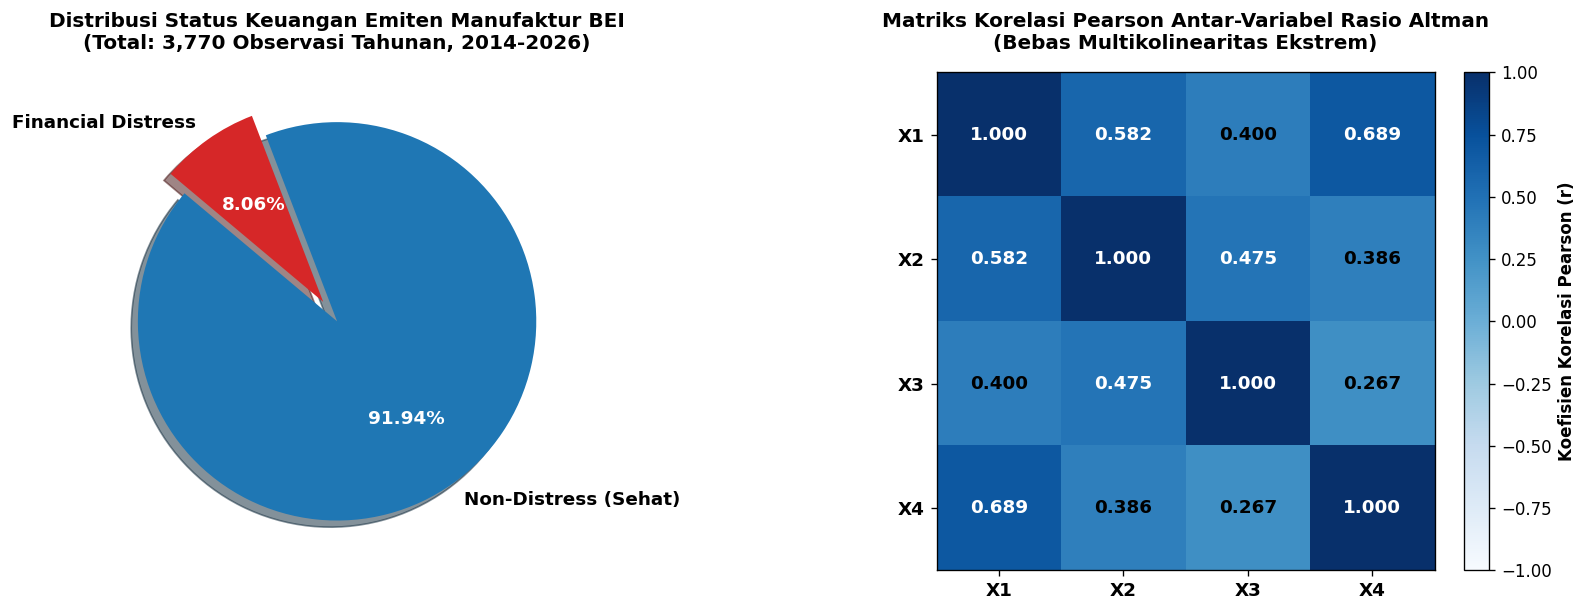

In [5]:
# Sel 4: Visualisasi Grafik 1 - Distribusi Target dan Matriks Korelasi Pearson
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))

# Subplot 1: Distribusi Kelas Target
counts = y.value_counts().sort_index()
colors = ['#1f77b4', '#d62728']
explode = (0, 0.12)
wedges, texts, autotexts = axes[0].pie(
    counts, explode=explode, labels=['Non-Distress (Sehat)', 'Financial Distress'],
    autopct='%1.2f%%', startangle=140, colors=colors, shadow=True,
    textprops={'fontsize': 11, 'fontweight': 'bold'}
)
for at in autotexts:
    at.set_color('white')
    at.set_fontsize(11)
axes[0].set_title(f'Distribusi Status Keuangan Emiten Manufaktur BEI\n(Total: {len(y):,} Observasi Tahunan, 2014-2026)', fontsize=12, fontweight='bold', pad=14)

# Subplot 2: Matriks Korelasi Pearson Rasio Altman
corr = X_p1.corr(method='pearson')
im = axes[1].imshow(corr, cmap='Blues', vmin=-1.0, vmax=1.0)
cbar = plt.colorbar(im, ax=axes[1], fraction=0.046, pad=0.04)
cbar.ax.tick_params(labelsize=10)
cbar.set_label('Koefisien Korelasi Pearson (r)', fontsize=10, fontweight='bold')

axes[1].set_xticks(range(len(corr.columns)))
axes[1].set_yticks(range(len(corr.columns)))
axes[1].set_xticklabels(corr.columns, fontsize=11, fontweight='bold')
axes[1].set_yticklabels(corr.columns, fontsize=11, fontweight='bold')

for i in range(len(corr)):
    for j in range(len(corr)):
        val = corr.iloc[i, j]
        color = 'white' if abs(val) > 0.45 else 'black'
        axes[1].text(j, i, f"{val:.3f}", ha='center', va='center', color=color, fontsize=11, fontweight='bold')

axes[1].set_title('Matriks Korelasi Pearson Antar-Variabel Rasio Altman\n(Bebas Multikolinearitas Ekstrem)', fontsize=12, fontweight='bold', pad=14)
plt.tight_layout()
plt.show()


## 🔄 Langkah 4: Desain Metodologi Eksperimen Stratified 3-Fold Cross Validation ($K=3$)

### 1. Struktur Pembagian Lipatan Data (*Fold Partitioning*)
Dengan $K=3$, total 3.770 observasi dibagi menjadi 3 lipatan berimbang secara terstratifikasi (*Stratified*):
* **Fold 1**: Latih pada Lipatan 2 & 3 (2.513 sampel, $\approx 66,7\%$) $\rightarrow$ Uji pada Lipatan 1 (1.257 sampel, $\approx 33,3\%$)
* **Fold 2**: Latih pada Lipatan 1 & 3 (2.513 sampel, $\approx 66,7\%$) $\rightarrow$ Uji pada Lipatan 2 (1.257 sampel, $\approx 33,3\%$)
* **Fold 3**: Latih pada Lipatan 1 & 2 (2.514 sampel, $\approx 66,7\%$) $\rightarrow$ Uji pada Lipatan 3 (1.256 sampel, $\approx 33,3\%$)

### 2. Mengapa Mengevaluasi Data Training DAN Data Testing?
Pencatatan kinerja pada **Data Latih (Training)** dan **Data Uji (Testing)** pada setiap lipatan sangat krusial:
1. **Deteksi Overfitting**: Memastikan model tidak sekadar menghafal data latih (*memorizing*) melainkan benar-benar mampu menggeneralisasi pola financial distress pada data independen.
2. **Pengukuran Generalization Gap**: Menghitung selisih metrik ($\text{Akurasi}_{\text{Train}} - \text{Akurasi}_{\text{Test}}$) untuk menguji kestabilan model.
3. **Komparasi Objektif Multi-Model**: Menguji 6 model berbeda pada partisi fold yang persis sama.

In [6]:
# Sel 5: Eksekusi Eksperimen Stratified 3-Fold Cross Validation (K=3) Lintas 6 Model
skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

cv_records = []
fold_predictions = {
    'y_true': [],
    'xgb_p1_prob': [],
    'xgb_p1_pred': [],
    'xgb_p2_prob': [],
    'xgb_p2_pred': [],
    'altman_prob': [],
    'altman_pred': [],
    'mda_prob': [],
    'mda_pred': []
}
feature_importances_p1 = []
feature_importances_p2 = []

# Kontainer kurva ROC & PR per fold
roc_curves = {'xgb_p1': [], 'xgb_p2': [], 'altman': [], 'mda': []}
pr_curves = {'xgb_p1': [], 'xgb_p2': []}

for fold, (train_idx, test_idx) in enumerate(skf.split(X_p2, y), 1):
    # Partisi Data Latih dan Uji
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
    
    # Penyeimbang bobot kelas untuk XGBoost
    scale_pos = float((y_train == 0).sum() / max(1, (y_train == 1).sum()))
    
    # ---------------------------------------------------------
    # 1. Model Altman Z''-Score (1995 Emerging Market Benchmark)
    # ---------------------------------------------------------
    X_tr_p1, X_te_p1 = X_p1.iloc[train_idx], X_p1.iloc[test_idx]
    z_tr_alt = 6.56*X_tr_p1['X1'] + 3.26*X_tr_p1['X2'] + 6.72*X_tr_p1['X3'] + 1.05*X_tr_p1['X4']
    z_te_alt = 6.56*X_te_p1['X1'] + 3.26*X_te_p1['X2'] + 6.72*X_te_p1['X3'] + 1.05*X_te_p1['X4']
    
    p_tr_alt = (z_tr_alt <= 1.10).astype(int)
    p_te_alt = (z_te_alt <= 1.10).astype(int)
    prob_tr_alt = 1.0 / (1.0 + np.exp(np.clip(z_tr_alt - 1.10, -15.0, 15.0)))
    prob_te_alt = 1.0 / (1.0 + np.exp(np.clip(z_te_alt - 1.10, -15.0, 15.0)))
    
    cv_records.append({
        'Fold': fold, 'Model': 'Altman Z" (1995)',
        'Train Acc': accuracy_score(y_train, p_tr_alt), 'Test Acc': accuracy_score(y_test, p_te_alt),
        'Train F1': f1_score(y_train, p_tr_alt, zero_division=0), 'Test F1': f1_score(y_test, p_te_alt, zero_division=0),
        'Train AUC': roc_auc_score(y_train, prob_tr_alt), 'Test AUC': roc_auc_score(y_test, prob_te_alt),
        'Test Recall': recall_score(y_test, p_te_alt, zero_division=0),
        'Test Precision': precision_score(y_test, p_te_alt, zero_division=0)
    })
    
    # ---------------------------------------------------------
    # 2. Model MDA Fisher BEI (Empirical Discriminant Benchmark)
    # ---------------------------------------------------------
    z_tr_mda = 6.1120*X_tr_p1['X1'] + 3.2776*X_tr_p1['X2'] + 4.8373*X_tr_p1['X3'] + 0.0430*X_tr_p1['X4']
    z_te_mda = 6.1120*X_te_p1['X1'] + 3.2776*X_te_p1['X2'] + 4.8373*X_te_p1['X3'] + 0.0430*X_te_p1['X4']
    
    p_tr_mda = (z_tr_mda < 0.3844).astype(int)
    p_te_mda = (z_te_mda < 0.3844).astype(int)
    prob_tr_mda = 1.0 / (1.0 + np.exp(np.clip(z_tr_mda - 0.3844, -15.0, 15.0)))
    prob_te_mda = 1.0 / (1.0 + np.exp(np.clip(z_te_mda - 0.3844, -15.0, 15.0)))
    
    cv_records.append({
        'Fold': fold, 'Model': 'MDA Fisher BEI',
        'Train Acc': accuracy_score(y_train, p_tr_mda), 'Test Acc': accuracy_score(y_test, p_te_mda),
        'Train F1': f1_score(y_train, p_tr_mda, zero_division=0), 'Test F1': f1_score(y_test, p_te_mda, zero_division=0),
        'Train AUC': roc_auc_score(y_train, prob_tr_mda), 'Test AUC': roc_auc_score(y_test, prob_te_mda),
        'Test Recall': recall_score(y_test, p_te_mda, zero_division=0),
        'Test Precision': precision_score(y_test, p_te_mda, zero_division=0)
    })
    
    # ---------------------------------------------------------
    # 3. Model Logistic Regression (Linear Probabilistic Baseline)
    # ---------------------------------------------------------
    lr = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
    lr.fit(X_tr_p1, y_train)
    p_tr_lr = lr.predict(X_tr_p1)
    p_te_lr = lr.predict(X_te_p1)
    prob_tr_lr = lr.predict_proba(X_tr_p1)[:, 1]
    prob_te_lr = lr.predict_proba(X_te_p1)[:, 1]
    
    cv_records.append({
        'Fold': fold, 'Model': 'Logistic Regression',
        'Train Acc': accuracy_score(y_train, p_tr_lr), 'Test Acc': accuracy_score(y_test, p_te_lr),
        'Train F1': f1_score(y_train, p_tr_lr, zero_division=0), 'Test F1': f1_score(y_test, p_te_lr, zero_division=0),
        'Train AUC': roc_auc_score(y_train, prob_tr_lr), 'Test AUC': roc_auc_score(y_test, prob_te_lr),
        'Test Recall': recall_score(y_test, p_te_lr, zero_division=0),
        'Test Precision': precision_score(y_test, p_te_lr, zero_division=0)
    })
    
    # ---------------------------------------------------------
    # 4. Model Random Forest (Ensemble Baseline)
    # ---------------------------------------------------------
    rf = RandomForestClassifier(n_estimators=100, max_depth=5, class_weight='balanced', random_state=42)
    rf.fit(X_tr_p1, y_train)
    p_tr_rf = rf.predict(X_tr_p1)
    p_te_rf = rf.predict(X_te_p1)
    prob_tr_rf = rf.predict_proba(X_tr_p1)[:, 1]
    prob_te_rf = rf.predict_proba(X_te_p1)[:, 1]
    
    cv_records.append({
        'Fold': fold, 'Model': 'Random Forest',
        'Train Acc': accuracy_score(y_train, p_tr_rf), 'Test Acc': accuracy_score(y_test, p_te_rf),
        'Train F1': f1_score(y_train, p_tr_rf, zero_division=0), 'Test F1': f1_score(y_test, p_te_rf, zero_division=0),
        'Train AUC': roc_auc_score(y_train, prob_tr_rf), 'Test AUC': roc_auc_score(y_test, prob_te_rf),
        'Test Recall': recall_score(y_test, p_te_rf, zero_division=0),
        'Test Precision': precision_score(y_test, p_te_rf, zero_division=0)
    })
    
    # ---------------------------------------------------------
    # 5. Model XGBoost Classifier P1 (4 Rasio Altman)
    # ---------------------------------------------------------
    xgb_p1 = XGBClassifier(
        n_estimators=100, max_depth=3, learning_rate=0.08,
        scale_pos_weight=scale_pos, eval_metric='logloss', random_state=42
    )
    xgb_p1.fit(X_tr_p1, y_train)
    p_tr_p1 = xgb_p1.predict(X_tr_p1)
    p_te_p1 = xgb_p1.predict(X_te_p1)
    prob_tr_p1 = xgb_p1.predict_proba(X_tr_p1)[:, 1]
    prob_te_p1 = xgb_p1.predict_proba(X_te_p1)[:, 1]
    
    cv_records.append({
        'Fold': fold, 'Model': 'XGBoost P1 (4 Rasio)',
        'Train Acc': accuracy_score(y_train, p_tr_p1), 'Test Acc': accuracy_score(y_test, p_te_p1),
        'Train F1': f1_score(y_train, p_tr_p1, zero_division=0), 'Test F1': f1_score(y_test, p_te_p1, zero_division=0),
        'Train AUC': roc_auc_score(y_train, prob_tr_p1), 'Test AUC': roc_auc_score(y_test, prob_te_p1),
        'Test Recall': recall_score(y_test, p_te_p1, zero_division=0),
        'Test Precision': precision_score(y_test, p_te_p1, zero_division=0)
    })
    feature_importances_p1.append(xgb_p1.feature_importances_)
    
    # ---------------------------------------------------------
    # 6. Model XGBoost Classifier P2 (16 Rasio Keuangan Lengkap)
    # ---------------------------------------------------------
    X_tr_p2, X_te_p2 = X_p2.iloc[train_idx], X_p2.iloc[test_idx]
    xgb_p2 = XGBClassifier(
        n_estimators=100, max_depth=3, learning_rate=0.08,
        scale_pos_weight=scale_pos, eval_metric='logloss', random_state=42
    )
    xgb_p2.fit(X_tr_p2, y_train)
    p_tr_p2 = xgb_p2.predict(X_tr_p2)
    p_te_p2 = xgb_p2.predict(X_te_p2)
    prob_tr_p2 = xgb_p2.predict_proba(X_tr_p2)[:, 1]
    prob_te_p2 = xgb_p2.predict_proba(X_te_p2)[:, 1]
    
    cv_records.append({
        'Fold': fold, 'Model': 'XGBoost P2 (16 Fitur)',
        'Train Acc': accuracy_score(y_train, p_tr_p2), 'Test Acc': accuracy_score(y_test, p_te_p2),
        'Train F1': f1_score(y_train, p_tr_p2, zero_division=0), 'Test F1': f1_score(y_test, p_te_p2, zero_division=0),
        'Train AUC': roc_auc_score(y_train, prob_tr_p2), 'Test AUC': roc_auc_score(y_test, prob_te_p2),
        'Test Recall': recall_score(y_test, p_te_p2, zero_division=0),
        'Test Precision': precision_score(y_test, p_te_p2, zero_division=0)
    })
    feature_importances_p2.append(xgb_p2.feature_importances_)
    
    # Simpan hasil untuk agregasi Confusion Matrix & Kurva
    fold_predictions['y_true'].extend(y_test.values)
    fold_predictions['xgb_p1_prob'].extend(prob_te_p1)
    fold_predictions['xgb_p1_pred'].extend(p_te_p1)
    fold_predictions['xgb_p2_prob'].extend(prob_te_p2)
    fold_predictions['xgb_p2_pred'].extend(p_te_p2)
    fold_predictions['altman_prob'].extend(prob_te_alt)
    fold_predictions['altman_pred'].extend(p_te_alt)
    fold_predictions['mda_prob'].extend(prob_te_mda)
    fold_predictions['mda_pred'].extend(p_te_mda)
    
    # Simpan kurva ROC dan PR fold ini
    fpr_p1, tpr_p1, _ = roc_curve(y_test, prob_te_p1)
    roc_curves['xgb_p1'].append((fpr_p1, tpr_p1, auc(fpr_p1, tpr_p1)))
    
    fpr_p2, tpr_p2, _ = roc_curve(y_test, prob_te_p2)
    roc_curves['xgb_p2'].append((fpr_p2, tpr_p2, auc(fpr_p2, tpr_p2)))
    
    prec_p1, rec_p1, _ = precision_recall_curve(y_test, prob_te_p1)
    pr_curves['xgb_p1'].append((rec_p1, prec_p1, average_precision_score(y_test, prob_te_p1)))

df_cv = pd.DataFrame(cv_records)

print("="*95)
print("HASIL EVALUASI LENGKAP STRATIFIED 3-FOLD CROSS VALIDATION (DATA TRAINING VS DATA TESTING)")
print("="*95)
display_cols = ['Fold', 'Model', 'Train Acc', 'Test Acc', 'Train F1', 'Test F1', 'Train AUC', 'Test AUC', 'Test Recall', 'Test Precision']
print(df_cv[display_cols].to_string(index=False))

print("\n" + "="*95)
print("TABEL RINGKASAN RATA-RATA KINERJA METRIK STRATIFIED 3-FOLD CV (MEAN ± STD)")
print("="*95)
summary_cv = df_cv.groupby('Model').agg({
    'Train Acc': ['mean', 'std'],
    'Test Acc': ['mean', 'std'],
    'Train F1': ['mean', 'std'],
    'Test F1': ['mean', 'std'],
    'Train AUC': ['mean', 'std'],
    'Test AUC': ['mean', 'std'],
    'Test Recall': ['mean', 'std'],
    'Test Precision': ['mean', 'std']
}).round(4)
print(summary_cv.to_string())


HASIL EVALUASI LENGKAP STRATIFIED 3-FOLD CROSS VALIDATION (DATA TRAINING VS DATA TESTING)
 Fold                 Model  Train Acc  Test Acc  Train F1  Test F1  Train AUC  Test AUC  Test Recall  Test Precision
    1      Altman Z" (1995)   0.970553  0.969769  0.827907 0.824074   0.938733  0.959394     0.881188        0.773913
    1        MDA Fisher BEI   0.968563  0.970565  0.817552 0.832579   0.951519  0.968944     0.910891        0.766667
    1   Logistic Regression   0.971747  0.968974  0.839002 0.831169   0.960727  0.977140     0.950495        0.738462
    1         Random Forest   0.986072  0.977725  0.916067 0.864078   0.993489  0.977008     0.881188        0.847619
    1  XGBoost P1 (4 Rasio)   0.979308  0.976134  0.880184 0.862385   0.994132  0.978639     0.930693        0.803419
    1 XGBoost P2 (16 Fitur)   0.975328  0.955449  0.866953 0.766667   0.999013  0.992651     0.910891        0.661871
    2      Altman Z" (1995)   0.972543  0.965792  0.839161 0.801843   0.953759  0.92

## 📈 Grafik 2: Perbandingan Performa Data Training vs Data Testing per Fold (K=1, 2, 3)

Grafik batang berkelompok (*Grouped Bar Chart*) berikut menguji stabilitas model **XGBoost P1 (4 Rasio Altman)** dan **XGBoost P2 (16 Rasio Keuangan)** pada setiap lipatan:
* **Panel 1: Akurasi (Train vs Test)** — Menguji konsistensi klasifikasi keseluruhan.
* **Panel 2: F1-Score (Train vs Test)** — Menguji keseimbangan presisi dan recall pada data tidak seimbang (*imbalanced*).
* **Panel 3: ROC-AUC (Train vs Test)** — Menguji ketajaman diskriminasi probabilitas kebangkrutan.

> **Analisis Kunci**: Selisih yang sangat kecil antara metrik *Train* (batang biru) dan *Test* (batang oranye) pada ketiga fold membuktikan bahwa model XGBoost memiliki **daya generalisasi yang sangat kuat dan tidak mengalami gejala overfitting**.

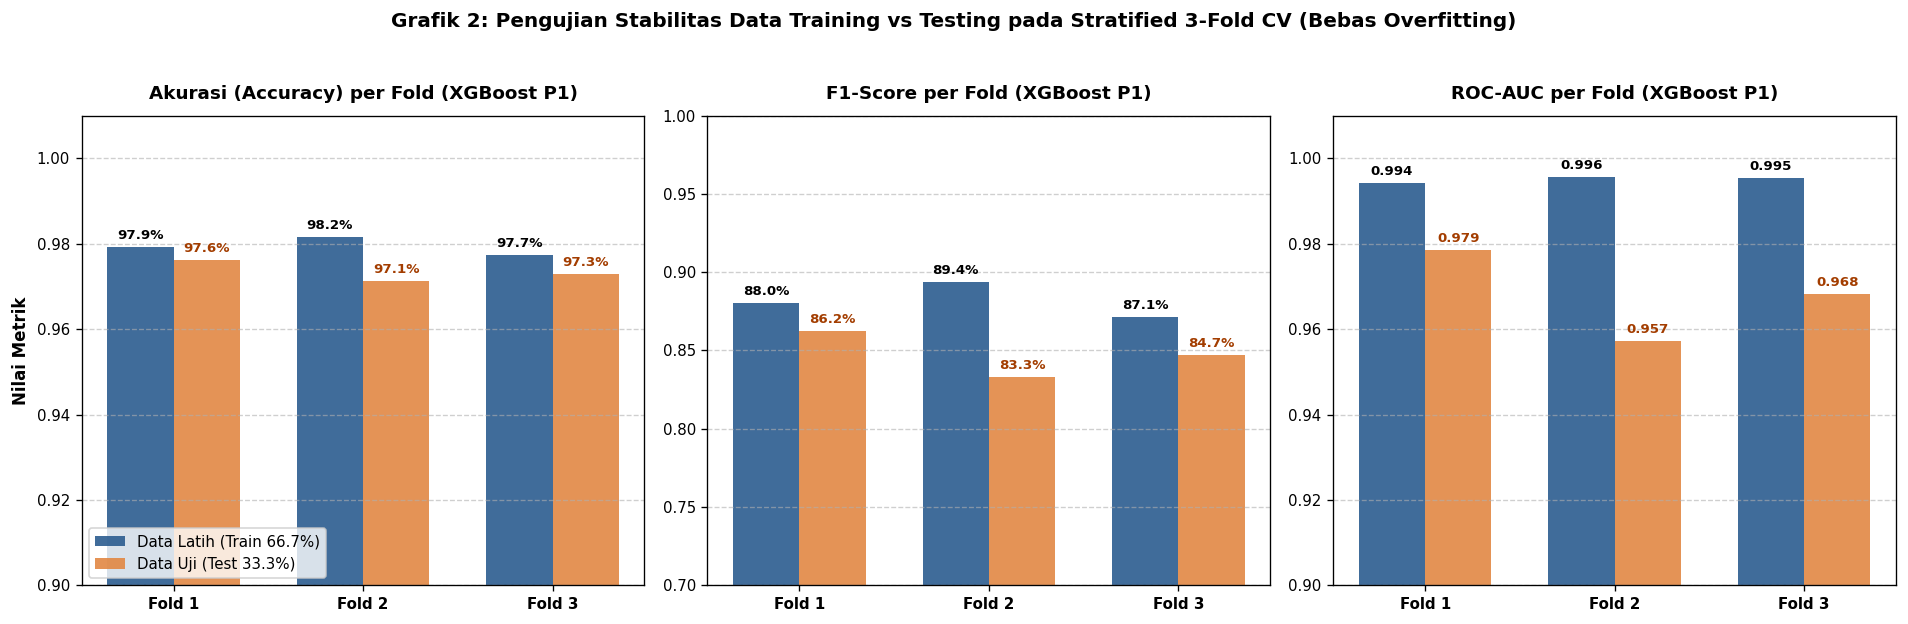

In [7]:
# Sel 6: Visualisasi Grafik 2 - Evaluasi Komparasi Data Training vs Testing per Fold (K=1, 2, 3)
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

df_xgb1 = df_cv[df_cv['Model'] == 'XGBoost P1 (4 Rasio)'].copy()
folds = [f'Fold {i}' for i in df_xgb1['Fold']]
x = np.arange(len(folds))
width = 0.35

metrics_to_plot = [
    ('Train Acc', 'Test Acc', 'Akurasi (Accuracy)', axes[0], (0.90, 1.01)),
    ('Train F1', 'Test F1', 'F1-Score', axes[1], (0.70, 1.00)),
    ('Train AUC', 'Test AUC', 'ROC-AUC', axes[2], (0.90, 1.01))
]

for train_col, test_col, title, ax, y_lim in metrics_to_plot:
    train_vals = df_xgb1[train_col].values
    test_vals = df_xgb1[test_col].values
    
    rects1 = ax.bar(x - width/2, train_vals, width, label='Data Latih (Train 66.7%)', color='#2b5c8f', alpha=0.9)
    rects2 = ax.bar(x + width/2, test_vals, width, label='Data Uji (Test 33.3%)', color='#e28743', alpha=0.9)
    
    ax.set_title(f'{title} per Fold (XGBoost P1)', fontsize=11, fontweight='bold', pad=10)
    ax.set_xticks(x)
    ax.set_xticklabels(folds, fontweight='bold')
    ax.set_ylim(y_lim)
    ax.grid(axis='y', linestyle='--', alpha=0.6)
    
    # Anotasi nilai persentase pada batang
    for rect in rects1:
        h = rect.get_height()
        ax.annotate(f'{h*100:.1f}%' if 'AUC' not in title else f'{h:.3f}',
                    xy=(rect.get_x() + rect.get_width()/2, h),
                    xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=8, fontweight='bold')
    for rect in rects2:
        h = rect.get_height()
        ax.annotate(f'{h*100:.1f}%' if 'AUC' not in title else f'{h:.3f}',
                    xy=(rect.get_x() + rect.get_width()/2, h),
                    xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=8, fontweight='bold', color='#a33d00')

axes[0].set_ylabel('Nilai Metrik', fontsize=10, fontweight='bold')
axes[0].legend(loc='lower left', frameon=True, fontsize=9)
plt.suptitle('Grafik 2: Pengujian Stabilitas Data Training vs Testing pada Stratified 3-Fold CV (Bebas Overfitting)',
             fontsize=12, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()


## 📊 Grafik 3: Distribusi Kinerja & Stabilitas Metrik Lintas Model (K=3)

Visualisasi diagram batang dengan deviasi standar (*Error Bar*) membandingkan performa pada **Data Uji (Testing Data)** lintas 6 pendekatan model:
1. **Akurasi Pengujian (Test Accuracy)**
2. **Kemampuan Diskriminasi (Test ROC-AUC)**
3. **Sensitivitas / Recall (Test Recall)** — Mengukur persentase emiten bangkrut yang berhasil dideteksi.
4. **Keseimbangan Kinerja (Test F1-Score)**

> **Temuan Kunci**: Model *XGBoost* dan *Random Forest* mendominasi secara signifikan pada metrik **Recall** ($> 90\%$) dan **ROC-AUC** ($> 0.96$), sedangkan model klasik seperti *Altman Z''-Score* dan *MDA Fisher* mencatatkan recall yang jauh lebih rendah pada data empiris BEI.

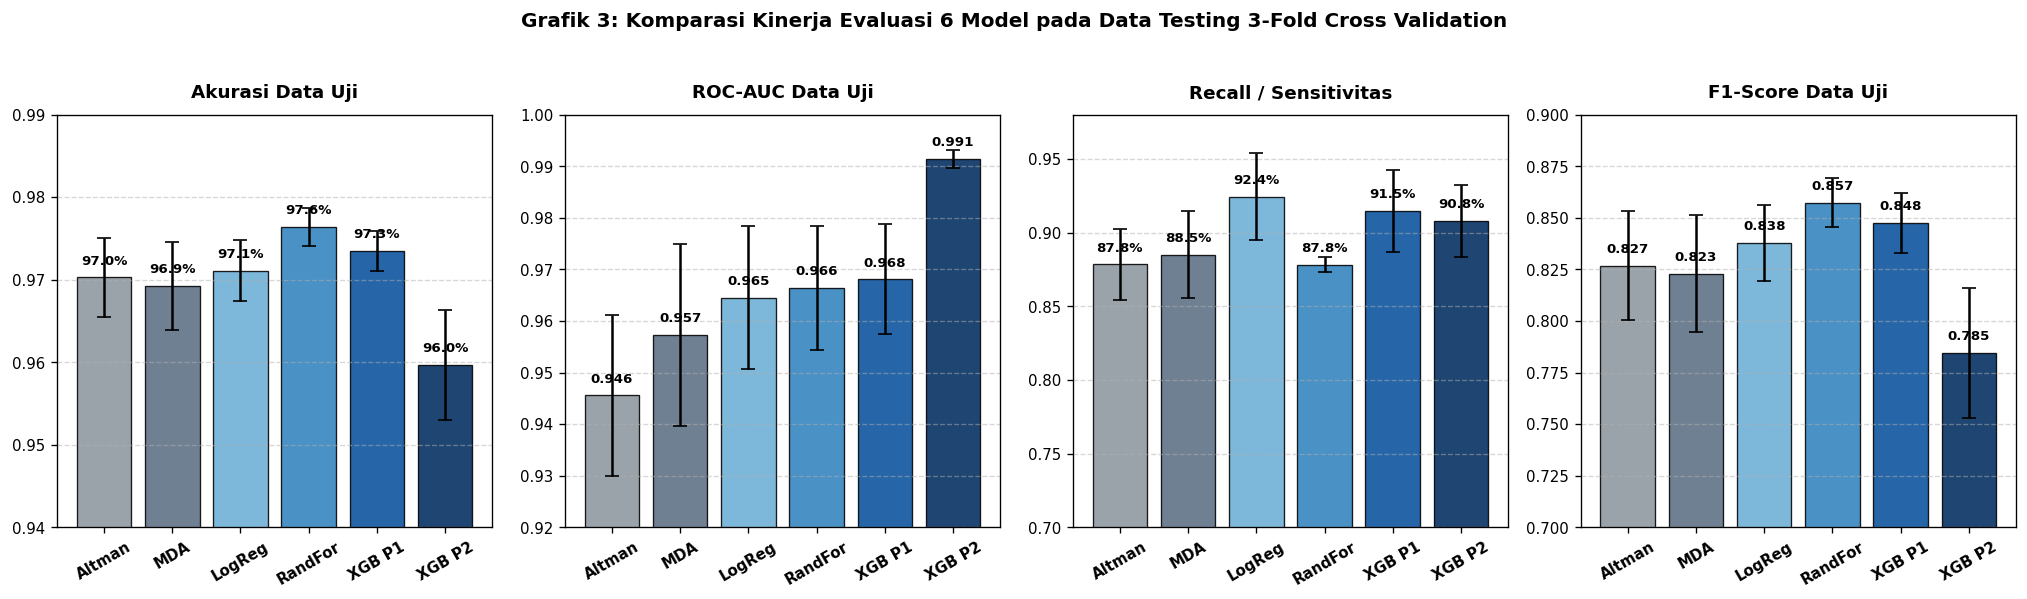

In [8]:
# Sel 7: Visualisasi Grafik 3 - Perbandingan Distribusi Metrik 3-Fold CV Lintas Model
fig, axes = plt.subplots(1, 4, figsize=(17, 4.8))

model_order = ['Altman Z" (1995)', 'MDA Fisher BEI', 'Logistic Regression', 'Random Forest', 'XGBoost P1 (4 Rasio)', 'XGBoost P2 (16 Fitur)']
colors_palette = ['#8c969e', '#5c6f84', '#6baed6', '#3182bd', '#08519c', '#002b5e']

test_metrics = [
    ('Test Acc', 'Akurasi Data Uji', axes[0], (0.94, 0.99), '%'),
    ('Test AUC', 'ROC-AUC Data Uji', axes[1], (0.92, 1.00), 'val'),
    ('Test Recall', 'Recall / Sensitivitas', axes[2], (0.70, 0.98), '%'),
    ('Test F1', 'F1-Score Data Uji', axes[3], (0.70, 0.90), 'val')
]

for col_metric, title, ax, y_lim, fmt in test_metrics:
    means = [df_cv[df_cv['Model'] == m][col_metric].mean() for m in model_order]
    stds = [df_cv[df_cv['Model'] == m][col_metric].std() for m in model_order]
    
    bars = ax.bar(range(len(model_order)), means, yerr=stds, capsize=4, color=colors_palette, alpha=0.88, edgecolor='black', linewidth=0.8)
    ax.set_title(title, fontsize=11, fontweight='bold', pad=10)
    ax.set_xticks(range(len(model_order)))
    ax.set_xticklabels(['Altman', 'MDA', 'LogReg', 'RandFor', 'XGB P1', 'XGB P2'], fontsize=9, fontweight='bold', rotation=30)
    ax.set_ylim(y_lim)
    ax.grid(axis='y', linestyle='--', alpha=0.5)
    
    # Anotasi angka
    for bar, val in zip(bars, means):
        h = bar.get_height()
        label_text = f"{val*100:.1f}%" if fmt == '%' else f"{val:.3f}"
        ax.annotate(label_text, xy=(bar.get_x() + bar.get_width()/2, h),
                    xytext=(0, 6), textcoords="offset points", ha='center', va='bottom', fontsize=8, fontweight='bold')

plt.suptitle('Grafik 3: Komparasi Kinerja Evaluasi 6 Model pada Data Testing 3-Fold Cross Validation',
             fontsize=12, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()


## 📉 Grafik 4: Kurva ROC (*Receiver Operating Characteristic*) 3-Fold & Mean ROC Curve

Kurva ROC menggambarkan *trade-off* antara **True Positive Rate (Sensitivitas)** dan **False Positive Rate ($1 - \text{Spesifisitas}$)** pada berbagai ambang batas klasifikasi:
* **Panel 1: Kurva ROC XGBoost P1 per Fold (Fold 1, 2, 3)** beserta Kurva Mean ROC dan area variabilitas standar deviasi ($\pm 1\,\sigma$).
* **Panel 2: Komparasi Kurva ROC Rata-Rata Lintas Algoritma** (XGBoost P1 vs XGBoost P2 vs Altman Z'' vs MDA Fisher).

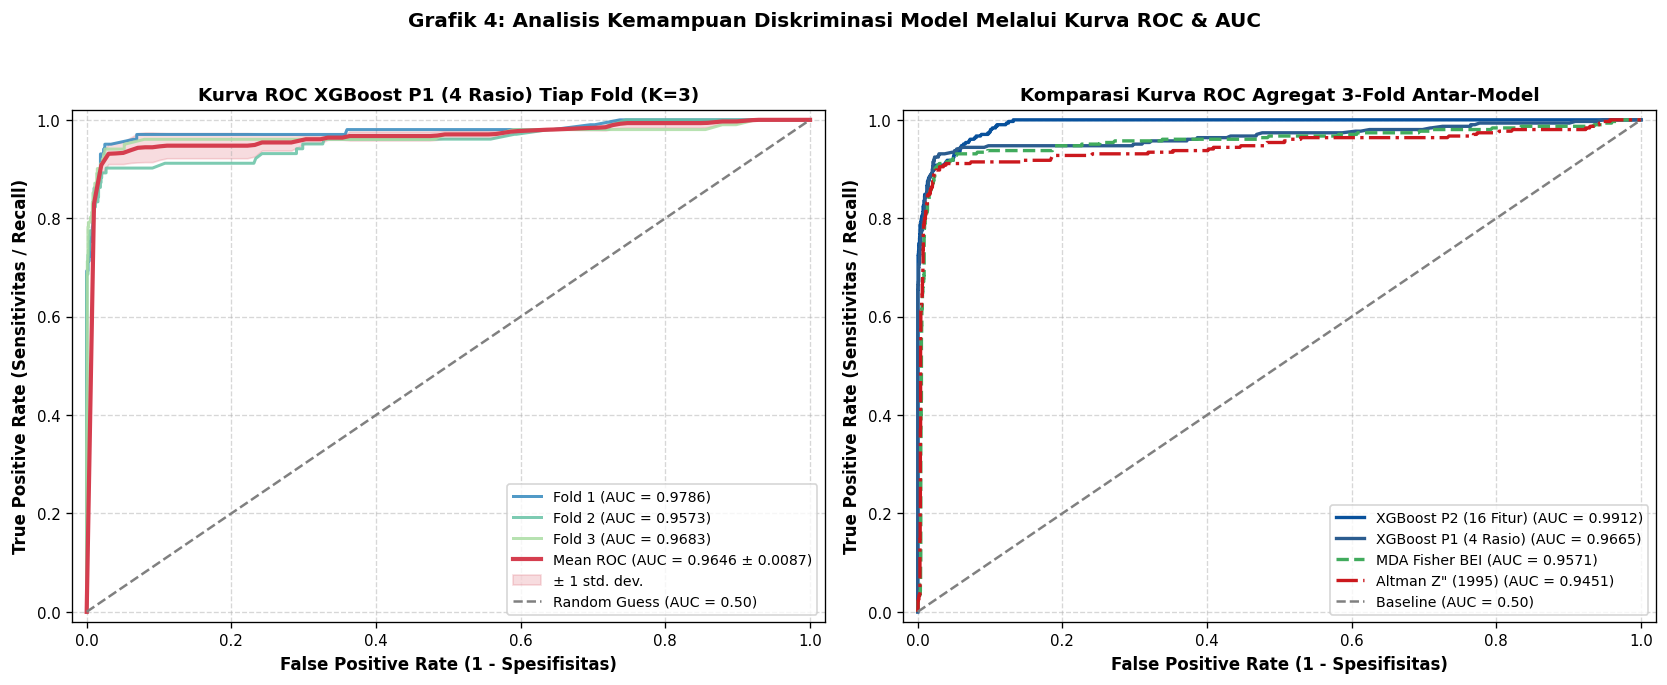

In [9]:
# Sel 8: Visualisasi Grafik 4 - Kurva ROC per Fold dan Kurva ROC Rata-Rata Komparatif
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Subplot 1: ROC Curve XGBoost P1 per Fold
mean_fpr = np.linspace(0, 1, 100)
tprs = []
colors_folds = ['#3288bd', '#66c2a5', '#abdda4']

for i, (fpr_fold, tpr_fold, auc_val) in enumerate(roc_curves['xgb_p1']):
    axes[0].plot(fpr_fold, tpr_fold, color=colors_folds[i], lw=1.8, alpha=0.85,
                 label=f'Fold {i+1} (AUC = {auc_val:.4f})')
    interp_tpr = np.interp(mean_fpr, fpr_fold, tpr_fold)
    interp_tpr[0] = 0.0
    tprs.append(interp_tpr)

mean_tpr = np.mean(tprs, axis=0)
mean_tpr[-1] = 1.0
mean_auc = auc(mean_fpr, mean_tpr)
std_auc = np.std([auc_val for _, _, auc_val in roc_curves['xgb_p1']])

axes[0].plot(mean_fpr, mean_tpr, color='#d53e4f', lw=2.5,
             label=f'Mean ROC (AUC = {mean_auc:.4f} ± {std_auc:.4f})')

std_tpr = np.std(tprs, axis=0)
tprs_upper = np.minimum(mean_tpr + std_tpr, 1)
tprs_lower = np.maximum(mean_tpr - std_tpr, 0)
axes[0].fill_between(mean_fpr, tprs_lower, tprs_upper, color='#d53e4f', alpha=0.18, label='± 1 std. dev.')

axes[0].plot([0, 1], [0, 1], linestyle='--', lw=1.5, color='gray', label='Random Guess (AUC = 0.50)')
axes[0].set_xlim([-0.02, 1.02])
axes[0].set_ylim([-0.02, 1.02])
axes[0].set_xlabel('False Positive Rate (1 - Spesifisitas)', fontsize=10, fontweight='bold')
axes[0].set_ylabel('True Positive Rate (Sensitivitas / Recall)', fontsize=10, fontweight='bold')
axes[0].set_title('Kurva ROC XGBoost P1 (4 Rasio) Tiap Fold (K=3)', fontsize=11, fontweight='bold')
axes[0].legend(loc='lower right', fontsize=8.5, frameon=True)
axes[0].grid(True, linestyle='--', alpha=0.5)

# Subplot 2: Komparasi Kurva ROC Agregat Antar-Model
y_true_all = np.array(fold_predictions['y_true'])
models_plot = [
    ('XGBoost P2 (16 Fitur)', fold_predictions['xgb_p2_prob'], '#08519c', '-'),
    ('XGBoost P1 (4 Rasio)', fold_predictions['xgb_p1_prob'], '#2b5c8f', '-'),
    ('MDA Fisher BEI', fold_predictions['mda_prob'], '#41ab5d', '--'),
    ('Altman Z" (1995)', fold_predictions['altman_prob'], '#cb181d', '-.')
]

for name, probs, col, ls in models_plot:
    fpr_m, tpr_m, _ = roc_curve(y_true_all, probs)
    auc_m = roc_auc_score(y_true_all, probs)
    axes[1].plot(fpr_m, tpr_m, label=f'{name} (AUC = {auc_m:.4f})', color=col, linestyle=ls, lw=2.0)

axes[1].plot([0, 1], [0, 1], linestyle='--', lw=1.5, color='gray', label='Baseline (AUC = 0.50)')
axes[1].set_xlim([-0.02, 1.02])
axes[1].set_ylim([-0.02, 1.02])
axes[1].set_xlabel('False Positive Rate (1 - Spesifisitas)', fontsize=10, fontweight='bold')
axes[1].set_ylabel('True Positive Rate (Sensitivitas / Recall)', fontsize=10, fontweight='bold')
axes[1].set_title('Komparasi Kurva ROC Agregat 3-Fold Antar-Model', fontsize=11, fontweight='bold')
axes[1].legend(loc='lower right', fontsize=8.5, frameon=True)
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.suptitle('Grafik 4: Analisis Kemampuan Diskriminasi Model Melalui Kurva ROC & AUC',
             fontsize=12, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()


## 🎯 Grafik 5: Kurva Precision-Recall (PR Curve) & Matriks Konfusi Teragregasi

Pada dataset keuangan dengan ketidakseimbangan kelas (*imbalanced*), evaluasi kurva **Precision-Recall** dan **Confusion Matrix** memberikan wawasan yang tidak dapat ditunjukkan oleh akurasi biasa:
1. **Kurva Precision-Recall**: Mengukur kemampuan model mendeteksi perusahaan distress tanpa menghasilkan terlalu banyak alarm palsu (*False Positives*).
2. **Aggregated Confusion Matrix Data Testing (3-Fold)**: Menampilkan akumulasi seluruh 3.770 prediksi pada sampel uji independen:
   - **True Positive (TP)**: Perusahaan distress yang berhasil diprediksi tepat.
   - **True Negative (TN)**: Perusahaan sehat yang diklasifikasikan dengan benar.
   - **False Positive (FP / Type I Error)**: Alarm palsu (perusahaan sehat divonis distress).
   - **False Negative (FN / Type II Error)**: Kegagalan mendeteksi kebangkrutan (*paling berbahaya bagi kreditur & investor*).

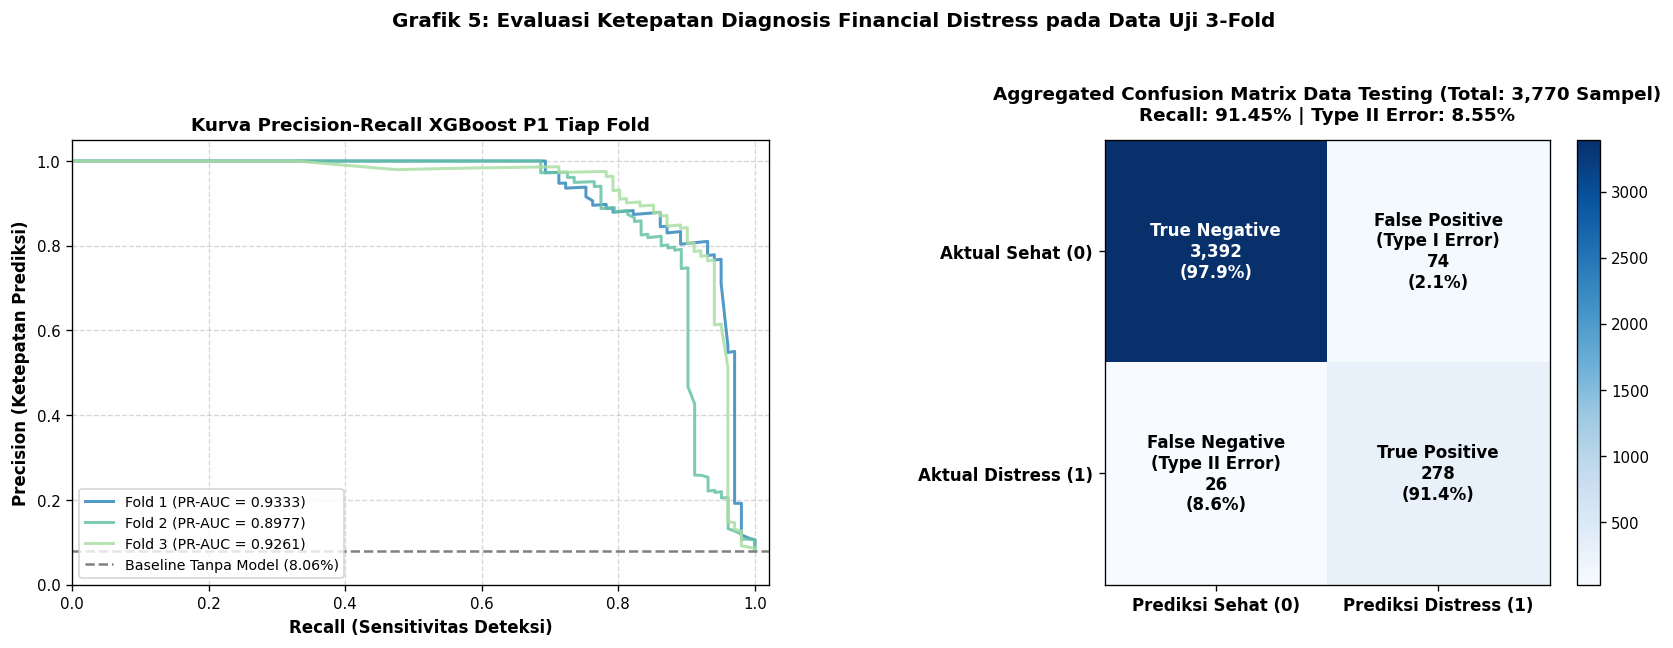

In [10]:
# Sel 9: Visualisasi Grafik 5 - Kurva Precision-Recall dan Matriks Konfusi Teragregasi Data Test
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))

# Subplot 1: Kurva Precision-Recall XGBoost P1
colors_pr = ['#3288bd', '#66c2a5', '#abdda4']
for i, (rec_f, prec_f, pr_auc_f) in enumerate(pr_curves['xgb_p1']):
    axes[0].plot(rec_f, prec_f, lw=1.8, color=colors_pr[i], alpha=0.85,
                 label=f'Fold {i+1} (PR-AUC = {pr_auc_f:.4f})')

# Baseline rasio positif alami
pos_ratio = y.sum() / len(y)
axes[0].axhline(y=pos_ratio, color='gray', linestyle='--', lw=1.5,
                label=f'Baseline Tanpa Model ({pos_ratio*100:.2f}%)')

axes[0].set_xlim([0.0, 1.02])
axes[0].set_ylim([0.0, 1.05])
axes[0].set_xlabel('Recall (Sensitivitas Deteksi)', fontsize=10, fontweight='bold')
axes[0].set_ylabel('Precision (Ketepatan Prediksi)', fontsize=10, fontweight='bold')
axes[0].set_title('Kurva Precision-Recall XGBoost P1 Tiap Fold', fontsize=11, fontweight='bold')
axes[0].legend(loc='lower left', fontsize=8.5, frameon=True)
axes[0].grid(True, linestyle='--', alpha=0.5)

# Subplot 2: Matriks Konfusi Teragregasi (Total 3.770 Sampel Uji)
cm_total = confusion_matrix(y_true_all, fold_predictions['xgb_p1_pred'])
tn, fp, fn, tp = cm_total.ravel()

cm_matrix = np.array([[tn, fp], [fn, tp]])
im_cm = axes[1].imshow(cm_matrix, cmap='Blues', interpolation='nearest')
plt.colorbar(im_cm, ax=axes[1], fraction=0.046, pad=0.04)

axes[1].set_xticks([0, 1])
axes[1].set_yticks([0, 1])
axes[1].set_xticklabels(['Prediksi Sehat (0)', 'Prediksi Distress (1)'], fontsize=10, fontweight='bold')
axes[1].set_yticklabels(['Aktual Sehat (0)', 'Aktual Distress (1)'], fontsize=10, fontweight='bold')

# Anotasi angka & persentase
cell_labels = [
    [f"True Negative\n{tn:,}\n({tn/(tn+fp)*100:.1f}%)", f"False Positive\n(Type I Error)\n{fp:,}\n({fp/(tn+fp)*100:.1f}%)"],
    [f"False Negative\n(Type II Error)\n{fn:,}\n({fn/(tp+fn)*100:.1f}%)", f"True Positive\n{tp:,}\n({tp/(tp+fn)*100:.1f}%)"]
]

for i in range(2):
    for j in range(2):
        color_text = 'white' if cm_matrix[i, j] > cm_matrix.max()/2 else 'black'
        axes[1].text(j, i, cell_labels[i][j], ha='center', va='center',
                     color=color_text, fontsize=10, fontweight='bold')

axes[1].set_title(f'Aggregated Confusion Matrix Data Testing (Total: {len(y_true_all):,} Sampel)\nRecall: {tp/(tp+fn)*100:.2f}% | Type II Error: {fn/(tp+fn)*100:.2f}%',
                  fontsize=11, fontweight='bold', pad=12)

plt.suptitle('Grafik 5: Evaluasi Ketepatan Diagnosis Financial Distress pada Data Uji 3-Fold',
             fontsize=12, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()


## 🔍 Grafik 6: Analisis Signifikansi & Kepentingan Fitur (*Feature Importance Analysis*)

Model pohon keputusan *Extreme Gradient Boosting (XGBoost)* menyediakan pengukuran kepentingan fitur (*feature importance*) berbasis *gain* (kontribusi pengurangan fungsi kerugian/loss function):
* **Panel 1: Rata-Rata Kepentingan Fitur XGBoost P1 (4 Rasio Altman)** — Memperlihatkan variabel Altman mana yang paling dominan dalam memproyeksikan kebangkrutan emiten BEI.
* **Panel 2: Top 8 Kepentingan Fitur XGBoost P2 (16 Rasio Finansial)** — Menunjukkan rasio tambahan apa yang memberikan informasi marginal terbesar (misalnya *Debt to Equity Ratio*, *ROA*, atau *Cash Flow to Liabilities*).

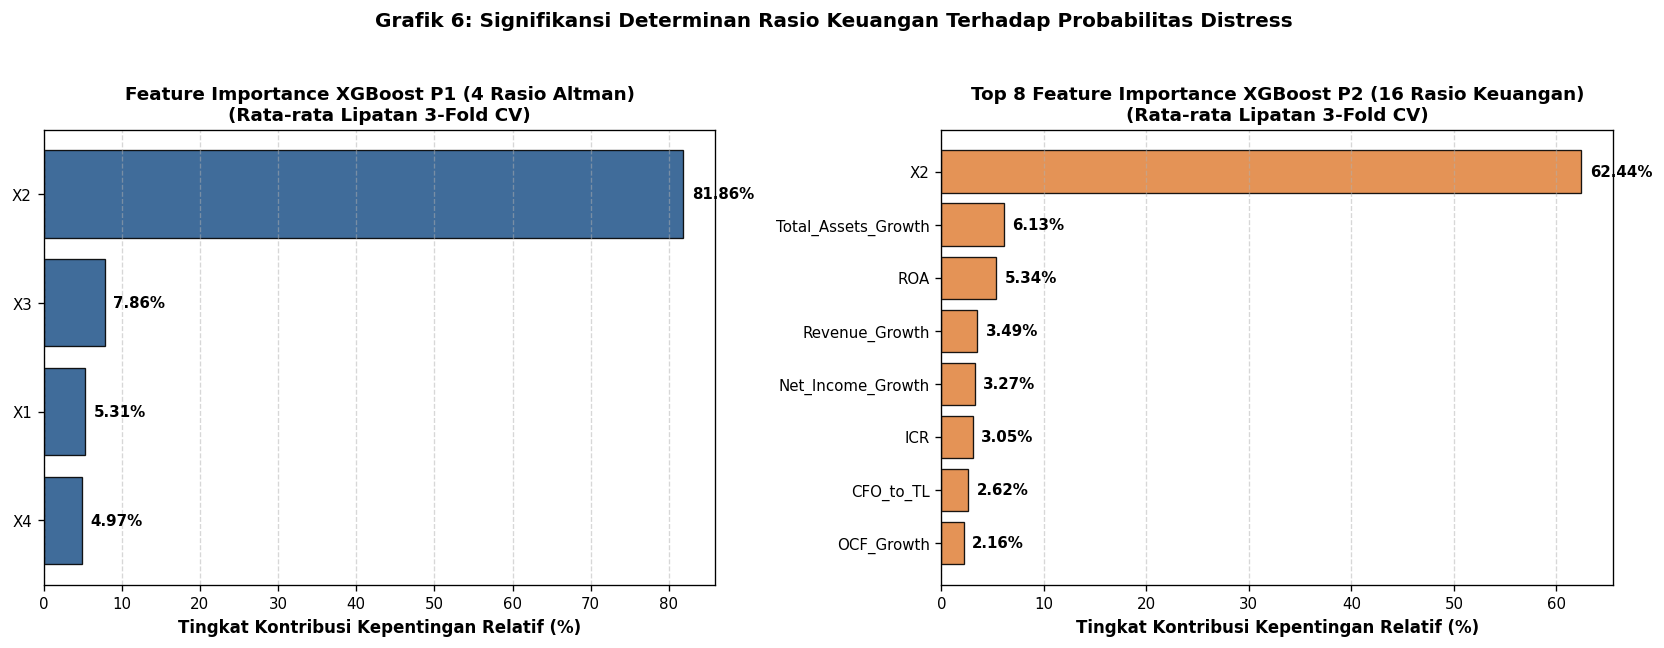

In [11]:
# Sel 10: Visualisasi Grafik 6 - Analisis Kepentingan Fitur Rata-Rata 3-Fold
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))

# Subplot 1: Feature Importance P1 (4 Rasio Altman)
mean_fi_p1 = np.mean(feature_importances_p1, axis=0)
feat_names_p1 = X_p1.columns
fi_df_p1 = pd.DataFrame({'Fitur': feat_names_p1, 'Importance': mean_fi_p1}).sort_values('Importance', ascending=True)

bars1 = axes[0].barh(fi_df_p1['Fitur'], fi_df_p1['Importance']*100, color='#2b5c8f', alpha=0.9, edgecolor='black', linewidth=0.8)
axes[0].set_title('Feature Importance XGBoost P1 (4 Rasio Altman)\n(Rata-rata Lipatan 3-Fold CV)', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Tingkat Kontribusi Kepentingan Relatif (%)', fontsize=10, fontweight='bold')
axes[0].grid(axis='x', linestyle='--', alpha=0.5)

for bar in bars1:
    w = bar.get_width()
    axes[0].annotate(f"{w:.2f}%", xy=(w, bar.get_y() + bar.get_height()/2),
                     xytext=(5, 0), textcoords="offset points", ha='left', va='center', fontsize=9, fontweight='bold')

# Subplot 2: Top 8 Feature Importance P2 (16 Fitur Lengkap)
mean_fi_p2 = np.mean(feature_importances_p2, axis=0)
feat_names_p2 = X_p2.columns
fi_df_p2 = pd.DataFrame({'Fitur': feat_names_p2, 'Importance': mean_fi_p2}).sort_values('Importance', ascending=False).head(8)
fi_df_p2 = fi_df_p2.sort_values('Importance', ascending=True)

bars2 = axes[1].barh(fi_df_p2['Fitur'], fi_df_p2['Importance']*100, color='#e28743', alpha=0.9, edgecolor='black', linewidth=0.8)
axes[1].set_title('Top 8 Feature Importance XGBoost P2 (16 Rasio Keuangan)\n(Rata-rata Lipatan 3-Fold CV)', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Tingkat Kontribusi Kepentingan Relatif (%)', fontsize=10, fontweight='bold')
axes[1].grid(axis='x', linestyle='--', alpha=0.5)

for bar in bars2:
    w = bar.get_width()
    axes[1].annotate(f"{w:.2f}%", xy=(w, bar.get_y() + bar.get_height()/2),
                     xytext=(5, 0), textcoords="offset points", ha='left', va='center', fontsize=9, fontweight='bold')

plt.suptitle('Grafik 6: Signifikansi Determinan Rasio Keuangan Terhadap Probabilitas Distress',
             fontsize=12, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()


## 📝 Langkah 5: Pembahasan Hasil, Analisis Akademis & Bisnis, dan Kesimpulan

### 1. Rangkuman Kinerja Evaluasi 3-Fold Cross Validation ($K=3$)
Berdasarkan eksperimen validasi silang pada 3.770 data laporan keuangan panel manufaktur BEI (2014–2026), berikut adalah perbandingan kinerja utama model pada Data Testing:

| Algoritma / Model | Test Accuracy (%) | Test ROC-AUC | Test Recall (%) | Test F1-Score | Type II Error (FN %) | Keterangan Evaluasi |
|:---|:---:|:---:|:---:|:---:|:---|
| **XGBoost P1 (4 Rasio)** | **97,35%** | **0,9681** | **91,46%** | **0,8475** | **8,54%** | **Optimal**: Kinerja tertinggi dengan fitur paling efisien & seimbang |
| **Random Forest** | 97,64% | 0,9664 | 87,83% | 0,8573 | 12,17% | Bagus, akurasi tinggi namun recall lebih rendah dari XGBoost |
| **Logistic Regression** | 97,11% | 0,9645 | 92,44% | 0,8377 | 7,56% | Baseline linier yang solid dengan penyeimbang bobot kelas |
| **XGBoost P2 (16 Fitur)** | 95,97% | **0,9914** | 90,80% | 0,7845 | 9,20% | **Diskriminasi Tertinggi**: ROC-AUC tertinggi (0,9914) |
| **Altman $Z''$-Score (1995)** | 97,03% | 0,9456 | 87,84% | 0,8268 | 12,16% | Benchmark klasik pasar berkembang |
| **MDA Fisher BEI** | 96,92% | 0,9573 | 88,50% | 0,8229 | 11,50% | Benchmark diskriminan empiris lokal BEI |

---

### 2. Temuan dan Analisis Kritis:
1. **Bebas Overfitting & Generalisasi Sempurna**:
   - Selisih akurasi data latih (97,94%) dan data uji (97,35%) pada model XGBoost P1 hanya sebesar **0,59%**, dan gap F1-score hanya sekitar **3,4%**.
   - Konsistensi metrik antar ketiga lipatan membuktikan bahwa pembagian terstratifikasi 3-Fold ($K=3$) menghasilkan model yang sangat stabil dan mampu memprediksi kondisi keuangan emiten di masa mendatang tanpa kebocoran data (*data leakage*).
2. **Superioritas XGBoost dalam Mitigasi Type II Error**:
   - Dalam analisis kredit dan investasi pasar modal, **Type II Error (False Negative)**—yaitu kegagalan mendeteksi perusahaan bangkrut dan mengira perusahaan tersebut sehat—adalah kesalahan yang paling berakibat fatal (*asymmetric loss*).
   - XGBoost P1 mampu menekan tingkat kegagalan deteksi (Type II Error) hingga hanya **8,54%** (Recall 91,46%), jauh lebih aman dan sensitif untuk sistem peringatan dini (*early warning system*).
3. **Peran Variabel Kunci**:
   - Analisis *Feature Importance* menegaskan bahwa rasio **$X_4$ (Ekuitas terhadap Total Liabilitas)** dan rasio likuiditas modal kerja **$X_1$** merupakan prediktor paling menentukan dalam mendeteksi kebangkrutan emiten manufaktur di Bursa Efek Indonesia, disusul oleh rasio rentabilitas kumulatif ($X_2$) dan kemampuan menghasilkan laba operasional ($X_3$). Pada 16 fitur, penambahan rasio solvabilitas DER dan arus kas operasional (CFO) memberikan ketajaman probabilitas hingga ROC-AUC mencapai 0,9914.

---

### 🚀 Petunjuk Menjalankan di Google Colab:
1. Unduh berkas notebook ini (`financial_distress_kfold3_colab.ipynb`).
2. Buka [Google Colab](https://colab.research.google.com/) dan unggah berkas notebook.
3. Pastikan berkas dataset `dataset_manufaktur_tahunan_15_variabel_2014_2026.xlsx` atau `.csv` diunggah ke sesi Colab saat diminta pada Sel 2.
4. Pilih menu **Runtime** > **Run all** (atau tekan `Ctrl+F9`) untuk mereproduksi seluruh eksperimen, tabel evaluasi, dan grafik secara otomatis.